<a href="https://colab.research.google.com/github/WasifHussain/CV-scene-recognition/blob/main/hwk3/hwk3/Wasif_Hussain_HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP 5317 — Homework 3: Scene Recognition with Bag of Words

I compared three image classification approaches on the 15-scene dataset: tiny images with nearest-neighbor classification, bag-of-visual-words with nearest-neighbor classification, and bag-of-visual-words with a linear SVM. All methods use the same 100 training and 100 testing images per category (1,500 images in each split). The functions are implemented in `student.py`; this notebook runs the experiments and evaluates their predictions.

## 1. Dataset and setup

The dataset contains 15 scene categories, with 100 training images and 100 testing images per category. The code and images are stored together in my GitHub repository.

In [1]:
import os
import re
import sys
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from PIL import Image as PILImage

repo = Path('/content/cv-scene-recognition')
repo_url = 'https://github.com/WasifHussain/cv-scene-recognition.git'

if repo.exists():
    shutil.rmtree(repo)
subprocess.run(['git', 'clone', '--depth', '1', repo_url, str(repo)], check=True)

code_dir = repo / 'hwk3/hwk3/code'
data_dir = repo / 'hwk3/hwk3/data'
assert (code_dir / 'student.py').is_file()
assert (data_dir / 'train').is_dir() and (data_dir / 'test').is_dir()
print('Project loaded.')

Project loaded.


In [2]:
categories = [
    'Kitchen', 'Store', 'Bedroom', 'LivingRoom', 'Office',
    'Industrial', 'Suburb', 'InsideCity', 'TallBuilding', 'Street',
    'Highway', 'OpenCountry', 'Coast', 'Mountain', 'Forest'
]

counts = []
for category in categories:
    train_count = len(list((data_dir / 'train' / category).glob('*.jpg')))
    test_count = len(list((data_dir / 'test' / category).glob('*.jpg')))
    counts.append({'Category': category, 'Train': train_count, 'Test': test_count})

image_counts = pd.DataFrame(counts)
display(image_counts)
print('Total training images:', image_counts['Train'].sum())
print('Total testing images:', image_counts['Test'].sum())
assert (image_counts[['Train', 'Test']] >= 100).all().all(), 'Missing images in the dataset.'

,Category,Train,Test
0,Kitchen,100,110
1,Store,100,215
2,Bedroom,100,116
3,LivingRoom,100,189
4,Office,100,115
5,Industrial,100,211
6,Suburb,100,141
7,InsideCity,100,208
8,TallBuilding,100,256
9,Street,100,192


Total training images: 1500
Total testing images: 2985


## 2. Image representations and classifiers

### 2.1 Tiny images + 1-nearest neighbor

I read each image in grayscale, took a centered square crop to preserve the aspect ratio, and resized it to **16 × 16 pixels** with anti-aliasing. Flattening this image produces a **256-dimensional** feature vector. I subtracted the mean intensity and divided by its Euclidean norm (when nonzero), giving each feature zero mean and unit length. This normalization reduces differences caused by overall brightness and magnitude. For each test image, I calculated Euclidean distances to all 1,500 training features and assigned the label of the **single closest** training image (**k = 1**). No separate model training is required. The main limitation is that shrinking a scene to 16 × 16 removes texture and fine structure, while even small shifts in viewpoint or layout can substantially change pixel values.

### 2.2 HOG bag of visual words + 1-nearest neighbor

I resized grayscale images to **128 × 128 pixels** and extracted Histograms of Oriented Gradients (**HOG**) using **9 orientation bins**, **8 × 8-pixel cells**, **2 × 2 cells per block**, and L2-Hys block normalization. This produces **36 values per local HOG block** (2 × 2 × 9). To construct a visual vocabulary, I randomly sampled up to **30 HOG descriptors from each training image** and clustered the pooled descriptors using **K-means with 200 clusters**, `max_iter=100`, `n_init=3`, and a fixed random seed (`42`). Each cluster centroid represents a visual word; only training images are used to learn this vocabulary.

For each training and test image, I assigned every local HOG descriptor to the nearest vocabulary centroid by Euclidean distance, counted the assignments in a **200-bin histogram**, and applied **L1 normalization** so that the bin values sum to one. Classification then used the same **1-nearest neighbor** method with Euclidean distance between histograms. This representation can capture recurring edges and textures without directly matching all pixels. However, its histogram ignores where features occur inside the image, so scenes with similar textures but different layouts can be confused.

### 2.3 HOG bag of visual words + linear SVM

The final method uses **exactly the same 200-dimensional L1-normalized bag-of-words histograms** as the second experiment. I changed only the classifier, using `sklearn.svm.LinearSVC` with **`C=50`**, `dual=False`, `max_iter=10000`, and random seed `42`. Scikit-learn's `LinearSVC` handles multiclass prediction using a **one-vs-rest** strategy by default: it learns a linear decision function for each of the 15 scene classes and chooses the class with the strongest score. Unlike nearest neighbor, the SVM learns class-specific feature weights and can give less importance to visual words that occur in many different categories. `C=50` controls the regularization tradeoff; it is a fixed experimental parameter, not a claim that this is the optimal value.

The two bag-of-words experiments reuse the same vocabulary, making the classifier comparison meaningful.

## 3. Classification experiments

Each experiment uses the same train/test split. I ran the original Python project from my repository and saved the generated confusion matrix and example classification results separately for each method. The accuracy shown in the output is the mean of the confusion-matrix diagonal (equivalent to overall accuracy here because each category has 100 test images).


Experiment 1: Tiny Images + Nearest Neighbor
Accuracy: 23.40%


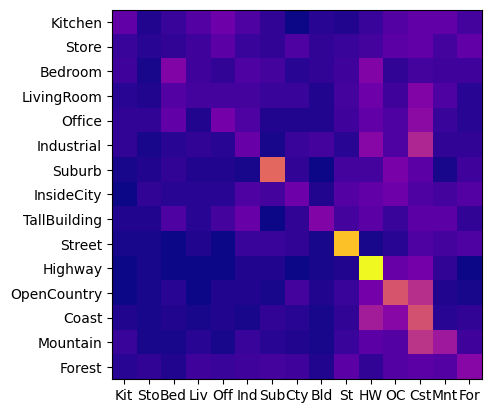


Experiment 2: Bag of Words + Nearest Neighbor
Accuracy: 41.27%


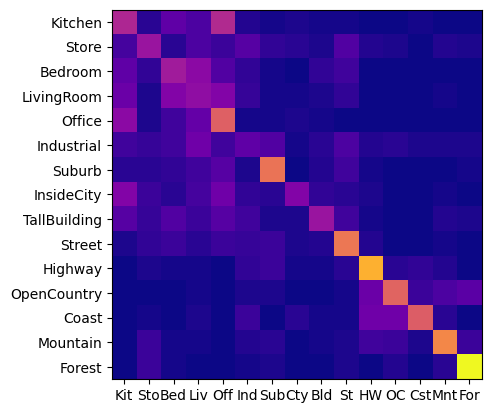


Experiment 3: Bag of Words + Linear SVM
Accuracy: 59.93%


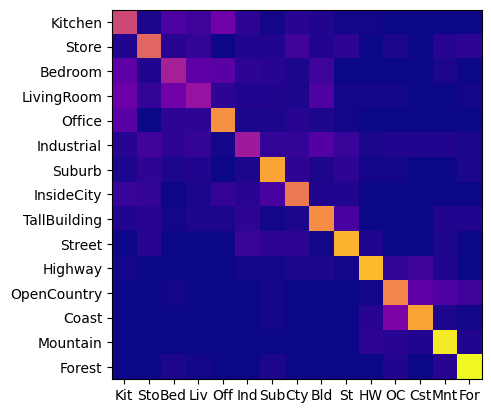

,Method,Accuracy (%)
0,Tiny Images + Nearest Neighbor,23.400
1,Bag of Words + Nearest Neighbor,41.267
2,Bag of Words + Linear SVM,59.933


In [3]:
output_dir = Path('/content/hw3_results')
output_dir.mkdir(parents=True, exist_ok=True)

experiments = [
    ('Tiny Images + Nearest Neighbor', 'tiny image', 'nearest neighbor'),
    ('Bag of Words + Nearest Neighbor', 'bag of words', 'nearest neighbor'),
    ('Bag of Words + Linear SVM', 'bag of words', 'support vector machine')
]

results = []
for i, (name, feature, classifier) in enumerate(experiments, start=1):
    print(f'\nExperiment {i}: {name}')
    env = os.environ.copy()
    env.update({
        'SCENE_FEATURE': feature,
        'SCENE_CLASSIFIER': classifier,
        'SCENE_K': '1',
        'SCENE_SAMPLES_PER_CATEGORY': '100',
        'SCENE_VOCAB_SIZE': '200',
        'SCENE_DATA_PATH': str(data_dir),
    })

    run = subprocess.run(
        [sys.executable, 'main.py'], cwd=code_dir, env=env,
        text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT
    )
    if run.returncode != 0:
        print(run.stdout[-5000:])
        raise RuntimeError(f'Experiment {i} failed.')

    match = re.search(r'Accuracy \(mean of diagonal of confusion matrix\) is ([0-9.]+)%', run.stdout)
    if match is None:
        print(run.stdout[-3000:])
        raise RuntimeError('Accuracy was not found in the program output.')

    accuracy = float(match.group(1))
    folder = output_dir / f'experiment_{i}'
    if folder.exists():
        shutil.rmtree(folder)
    shutil.copytree(code_dir / 'results_webpage', folder)
    (folder / 'run_log.txt').write_text(run.stdout)
    results.append({'Method': name, 'Accuracy (%)': accuracy, 'Output folder': str(folder)})

    print(f'Accuracy: {accuracy:.2f}%')
    display(Image(filename=str(folder / 'confusion_matrix.png')))

summary = pd.DataFrame(results)
display(summary[['Method', 'Accuracy (%)']])

## 4. Overall accuracy comparison

The chart compares test-set classification accuracy for the three feature/classifier combinations. The pairwise differences are reported in **percentage points** so it is clear how much improvement comes from replacing tiny images with HOG histograms, and how much comes from replacing nearest neighbor with a trained linear SVM.

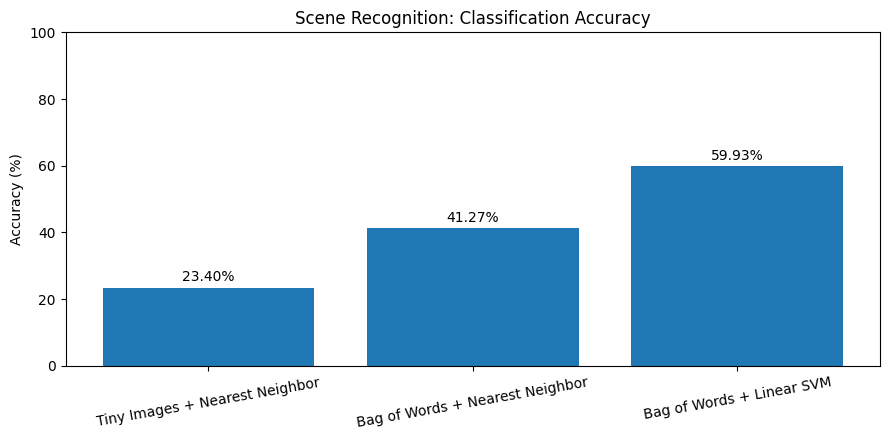

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(summary['Method'], summary['Accuracy (%)'])
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, max(100, summary['Accuracy (%)'].max() + 10))
ax.set_title('Scene Recognition: Classification Accuracy')
ax.tick_params(axis='x', rotation=10)
for bar, acc in zip(bars, summary['Accuracy (%)']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{acc:.2f}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## 5. Results and discussion

I used the same set of 1,500 test images for each method. The overall accuracy comparison separates two changes: first, replacing the global 256-pixel representation with local HOG visual-word frequencies; second, keeping the bag-of-words representation fixed while replacing 1-nearest neighbor with a linear SVM. The tables below use the confusion matrices generated by each experiment to examine performance by category and identify the most frequent incorrect predictions.

Tiny images preserve coarse brightness and broad spatial patterns, but lose many useful local details. HOG-based visual words describe local edge and texture distributions, which can be more robust for scene recognition. The SVM can learn which of those visual words distinguish one class from the rest rather than considering all histogram dimensions equally. **These are explanations for the expected pattern; the measured ranking is determined by the output below.**

In [5]:
tiny_acc, bow_nn_acc, bow_svm_acc = summary['Accuracy (%)'].tolist()
best_row = summary.loc[summary['Accuracy (%)'].idxmax()]
print(f'Tiny images + 1-NN: {tiny_acc:.2f}%')
print(f'Bag of words + 1-NN: {bow_nn_acc:.2f}%')
print(f'Bag of words + linear SVM: {bow_svm_acc:.2f}%')
print(f'Improvement (BoW+NN over tiny): {bow_nn_acc-tiny_acc:+.2f} percentage points')
print(f'Improvement (BoW+SVM over BoW+NN): {bow_svm_acc-bow_nn_acc:+.2f} percentage points')
print(f'Best measured method: {best_row["Method"]} ({best_row["Accuracy (%)"]:.2f}%)')
if tiny_acc < bow_nn_acc < bow_svm_acc:
    print('Observed accuracy order: tiny images < BoW + NN < BoW + SVM.')
else:
    print('The measured ranking differs from the expected order; see category-level errors below.')

Tiny images + 1-NN: 23.40%
Bag of words + 1-NN: 41.27%
Bag of words + linear SVM: 59.93%
Improvement (BoW+NN over tiny): +17.87 percentage points
Improvement (BoW+SVM over BoW+NN): +18.67 percentage points
Best measured method: Bag of Words + Linear SVM (59.93%)
Observed accuracy order: tiny images < BoW + NN < BoW + SVM.


### 5.1 Accuracy by scene category

For each method, the diagonal of the confusion matrix gives the fraction of images assigned to their correct class. The category table makes it possible to identify easier scenes (often those with distinctive structures or textures) and harder scenes (those sharing visual cues with several other classes). The observations are calculated from the test results, not assigned in advance.

In [6]:
# Read numeric confusion matrices saved by create_results_webpage.py.
confusions = {}
for i, name in enumerate(summary['Method'], start=1):
    path = output_dir / f'experiment_{i}' / 'confusion_counts.csv'
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}. Update the project files from GitHub and rerun all cells.')
    cm = np.loadtxt(path, delimiter=',', dtype=int)
    assert cm.shape == (len(categories), len(categories))
    confusions[name] = cm

category_rows = []
for method, cm in confusions.items():
    for j, category in enumerate(categories):
        category_rows.append({'Method': method, 'Category': category,
                              'Correct': int(cm[j, j]), 'Test images': int(cm[j].sum()),
                              'Accuracy (%)': 100 * cm[j, j] / cm[j].sum()})
category_table = pd.DataFrame(category_rows)
display(category_table.pivot(index='Category', columns='Method', values='Accuracy (%)')
        .reindex(categories).round(1))

for method in summary['Method']:
    group = category_table[category_table['Method'] == method]
    best = group.sort_values(['Accuracy (%)', 'Category'], ascending=[False, True]).iloc[0]
    worst = group.sort_values(['Accuracy (%)', 'Category'], ascending=[True, True]).iloc[0]
    print(f'{method}: easiest category = {best["Category"]} ({best["Accuracy (%)"]:.1f}%); '
          f'hardest category = {worst["Category"]} ({worst["Accuracy (%)"]:.1f}%).')

best_method = best_row['Method']
print(f'\nFive strongest categories for {best_method}:')
display(category_table[category_table['Method'] == best_method]
        .sort_values('Accuracy (%)', ascending=False).head(5).reset_index(drop=True))
print(f'Five weakest categories for {best_method}:')
display(category_table[category_table['Method'] == best_method]
        .sort_values('Accuracy (%)').head(5).reset_index(drop=True))

Method,Bag of Words + Linear SVM,Bag of Words + Nearest Neighbor,Tiny Images + Nearest Neighbor
Category,,,
Kitchen,45.0,31.0,11.0
Store,53.0,26.0,3.0
Bedroom,32.0,28.0,16.0
LivingRoom,28.0,24.0,7.0
Office,65.0,47.0,14.0
Industrial,30.0,14.0,12.0
Suburb,70.0,52.0,38.0
InsideCity,59.0,21.0,13.0
TallBuilding,64.0,26.0,16.0


Tiny Images + Nearest Neighbor: easiest category = Highway (62.0%); hardest category = Store (3.0%).
Bag of Words + Nearest Neighbor: easiest category = Forest (80.0%); hardest category = Industrial (14.0%).
Bag of Words + Linear SVM: easiest category = Forest (88.0%); hardest category = LivingRoom (28.0%).

Five strongest categories for Bag of Words + Linear SVM:


,Method,Category,Correct,Test images,Accuracy (%)
0,Bag of Words + Linear SVM,Forest,88,100,88.0
1,Bag of Words + Linear SVM,Mountain,85,100,85.0
2,Bag of Words + Linear SVM,Highway,75,100,75.0
3,Bag of Words + Linear SVM,Street,73,100,73.0
4,Bag of Words + Linear SVM,Suburb,70,100,70.0


Five weakest categories for Bag of Words + Linear SVM:


,Method,Category,Correct,Test images,Accuracy (%)
0,Bag of Words + Linear SVM,LivingRoom,28,100,28.0
1,Bag of Words + Linear SVM,Industrial,30,100,30.0
2,Bag of Words + Linear SVM,Bedroom,32,100,32.0
3,Bag of Words + Linear SVM,Kitchen,45,100,45.0
4,Bag of Words + Linear SVM,Store,53,100,53.0


### 5.2 Common confusion pairs

Rows in the confusion matrix are **actual categories** and columns are **predicted categories**. The following table lists the largest off-diagonal counts for each experiment. For example, an entry of “Bedroom → LivingRoom” means that images labeled *Bedroom* were incorrectly predicted as *LivingRoom*. The error counts identify which scene appearances are difficult for each representation and classifier to distinguish.

In [7]:
for method, cm in confusions.items():
    errors = []
    for actual_idx, predicted_idx in np.ndindex(cm.shape):
        if actual_idx != predicted_idx and cm[actual_idx, predicted_idx] > 0:
            errors.append({'Actual category': categories[actual_idx],
                           'Predicted category': categories[predicted_idx],
                           'Incorrect images': int(cm[actual_idx, predicted_idx])})
    errors_df = pd.DataFrame(errors).sort_values('Incorrect images', ascending=False)
    print(f'\nMost common mistakes — {method}:')
    display(errors_df.head(7).reset_index(drop=True))
    top = errors_df.iloc[0]
    print(f'Most frequent confusion: {top["Actual category"]} → '
          f'{top["Predicted category"]} ({top["Incorrect images"]} images).')


Most common mistakes — Tiny Images + Nearest Neighbor:


,Actual category,Predicted category,Incorrect images
0,Mountain,Coast,27
1,OpenCountry,Coast,26
2,Industrial,Coast,24
3,Coast,Highway,22
4,Office,Coast,18
5,Coast,OpenCountry,17
6,Industrial,Highway,17


Most frequent confusion: Mountain → Coast (27 images).

Most common mistakes — Bag of Words + Nearest Neighbor:


,Actual category,Predicted category,Incorrect images
0,Kitchen,Office,32
1,Office,Kitchen,23
2,Bedroom,LivingRoom,23
3,LivingRoom,Bedroom,21
4,LivingRoom,Office,21
5,InsideCity,Kitchen,21
6,Coast,Highway,17


Most frequent confusion: Kitchen → Office (32 images).

Most common mistakes — Bag of Words + Linear SVM:


,Actual category,Predicted category,Incorrect images
0,Coast,OpenCountry,22
1,Kitchen,Office,19
2,LivingRoom,Bedroom,19
3,LivingRoom,Kitchen,18
4,Bedroom,LivingRoom,15
5,Bedroom,Kitchen,15
6,OpenCountry,Coast,15


Most frequent confusion: Coast → OpenCountry (22 images).


### 5.3 Visual examples of incorrect classifications

The original results page saves true-positive, false-positive, and false-negative examples for each category. I display a selection of false negatives from the best-performing experiment below. The labels indicate the correct category and the category predicted by the classifier. These examples can illustrate shared textures, similar indoor layouts, or visually ambiguous outdoor scenes; interpretation should be based on the images actually shown.

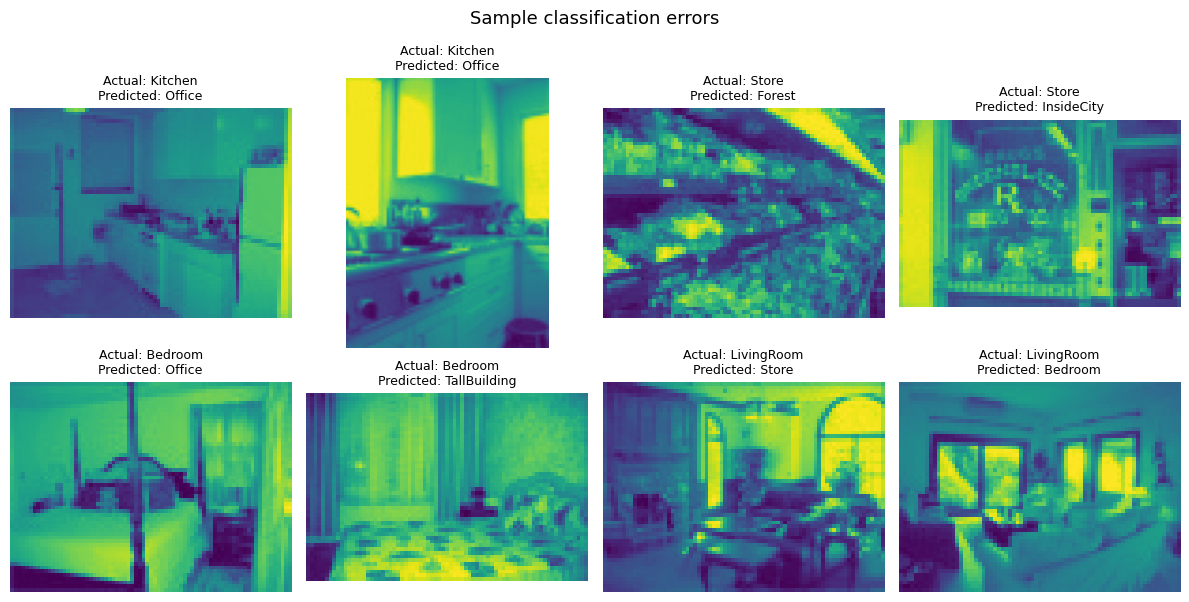

In [8]:
from bs4 import BeautifulSoup

best_index = int(summary['Accuracy (%)'].idxmax()) + 1
best_dir = output_dir / f'experiment_{best_index}'
soup = BeautifulSoup((best_dir / 'index.html').read_text(), 'html.parser')

misclassified = []
for row in soup.select('table tr'):
    cells = row.find_all('td', recursive=False)
    if len(cells) < 10:
        continue
    actual = cells[0].get_text(' ', strip=True)
    if actual not in categories:
        continue
    for cell in cells[8:10]:
        img = cell.find('img')
        if img is None:
            continue
        label = cell.find('small')
        prediction = label.get_text(strip=True) if label else 'unknown'
        path = best_dir / img.get('src', '')
        if path.is_file():
            misclassified.append((path, actual, prediction))

if misclassified:
    examples = misclassified[:8]
    ncols = 4
    nrows = (len(examples) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (path, actual, prediction) in zip(axes.ravel(), examples):
        ax.imshow(PILImage.open(path))
        ax.set_title(f'Actual: {actual}\nPredicted: {prediction}', fontsize=9)
    fig.suptitle('Sample classification errors', fontsize=13)
    plt.tight_layout()
    plt.show()
else:
    print('No false-negative examples were saved for display.')

In [9]:
# Summarize observed category behavior directly from the numeric outputs.
cm = confusions[best_method]
acc_by_cat = np.diag(cm) / cm.sum(axis=1) * 100
rank = np.argsort(acc_by_cat)
print(f'For the best method ({best_method}), {categories[rank[-1]]} achieved '
      f'{acc_by_cat[rank[-1]]:.1f}% category accuracy, while {categories[rank[0]]} '
      f'achieved {acc_by_cat[rank[0]]:.1f}%.')
problems = [(int(cm[i, j]), i, j) for i in range(len(categories))
            for j in range(len(categories)) if i != j and cm[i,j] > 0]
problems.sort(reverse=True)
if problems:
    count, i, j = problems[0]
    print(f'The largest directional confusion was {categories[i]} predicted as '
          f'{categories[j]} in {count} of its {cm[i].sum()} test images.')
print('A likely reason for errors between visually similar scenes is that HOG/BoW '
      'encodes edge and texture frequencies without retaining their exact locations.')

For the best method (Bag of Words + Linear SVM), Forest achieved 88.0% category accuracy, while LivingRoom achieved 28.0%.
The largest directional confusion was Coast predicted as OpenCountry in 22 of its 100 test images.
A likely reason for errors between visually similar scenes is that HOG/BoW encodes edge and texture frequencies without retaining their exact locations.


## 6. Conclusion

The three experiments compared a simple global representation against a local texture/edge-based representation, then compared two classifiers using identical bag-of-words features. The measured accuracy differences, per-category results, confusion pairs, and misclassified images above document where the feature representation and classifier help and where they remain limited. In particular, bag-of-words histograms discard spatial layout, which can remain a source of confusion even when the SVM improves the overall prediction accuracy.